# CCR reformer: moving catalyst, coke and the regenerator (#474)

A continuous catalyst regeneration (CCR) reformer runs at low pressure and high
severity because it never has to stop to burn its coke: the catalyst flows down
through the reactors, is lifted to a regenerator, and comes back clean.

`difflow_refinery.reforming.ccr` puts that on top of the semi-regen reformer:

* each bed runs at the activity `exp(-alpha C)` of the coke its catalyst carries
  (path-mean over the bed; `alpha` ILLUSTRATIVE);
* the coke rises bed by bed, `C_k = C_{k-1} + m_k / G` (`G` the circulation);
* the regenerator burns the spent coke in an O2-limited burn zone, fed by recycled
  flue gas so that the inlet is 0.8 % O2, which sets the burn-front temperature.

Literature values (UOP AFPM Q&A answers and UOP/IFP patents) are cited in the module
and the docs: design spent coke 5.25 wt%, 0.2 wt% left after the burn, 0.5-1.5 %
O2 in the burn zone, peak burn below 595 C, 52 lb coke/h burned per 1000 lb/h circulated.

In [1]:
import time
import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import replace

from difflow_refinery.reforming import CatalyticReformer, lean_naphtha, rich_naphtha
from difflow_refinery.reforming.ccr import (CCRReformer, CCRParams, Regenerator,
                                            RegeneratorParams, ccr_reformer_params, CCR_ENVELOPE)

## The base case

Four reactors, 3.5 bar separator, H2/HC 2.5, WAIT 500 C. The default circulation is the *design* circulation: the one that puts 5.25 wt% coke on the spent catalyst (UOP's design basis).

In [2]:
feed = lean_naphtha()
ccr = CCRReformer(ccr_reformer_params())
t = time.time()
base = ccr.solve(feed)
print(f"solved in {time.time() - t:.0f} s, {base.iterations} coke-activity passes")
print(base.summary())

solved in 50 s, 7 coke-activity passes


WAIT 500.0 C, WABT 469.6 C, P_sep 3.5 bar, H2/HC 2.50
reactor dT (K): -74.3, -70.2, -64.8, -53.3
reformate: 71.9 vol% (71.9 C5+), RON 102.0 (linear 95.9), MON 90.9, aromatics 74.8 vol%, benzene 2.05 vol%, RVP 2.0 psi
net H2 3.52 wt% of feed at 85.5 mol%; LPG 0.097 kg/s, fuel gas 0.006 kg/s
fired 34.77 MW, compressor 0.440 MW, coke 1.23 kg/h, cycle 116 d
CCR: circulation 24.4 kg/h, spent coke 5.25 wt%, activity 0.960, 0.907, 0.823, 0.678
regenerator: burn 1.23 kg/h (97% of capacity), peak 567 C (margin 28 K), reduction H2 0.0002 mol/s


In [3]:
b = base.balances()
print({k: f"{float(v):.1e}" for k, v in b.items() if k in ("mass", "carbon", "hydrogen", "coke", "catalyst_coke")})

{'mass': '-6.7e-14', 'carbon': '-5.3e-15', 'hydrogen': '-4.2e-13', 'coke': '1.8e-10', 'catalyst_coke': '1.8e-10'}


Coke made in the reactors equals coke burned in the regenerator, and each bed's coke balance closes, to the loop tolerance.

## Semi-regen limit

With infinite circulation and a perfectly clean regenerated catalyst every bed sees fresh catalyst: the CCR collapses to the semi-regen reformer at start of run.

In [4]:
p = ccr_reformer_params()
fresh = CCRReformer(p, CCRParams(circulation=1e9, regenerator=RegeneratorParams(coke_regen=0.0))).solve(feed)
semi = CatalyticReformer(p).solve(feed)
for k in ("reformate.RON", "reformate.yield_vol", "h2.net_mol_s"):
    print(f"{k:22s} CCR(G->inf) {float(fresh.outputs()[k]):10.5f}   semi-regen {float(semi.outputs()[k]):10.5f}")
print("fresh-catalyst RON vs design-circulation RON:",
      round(float(fresh.outputs()['reformate.RON']), 2), round(float(base.outputs()['reformate.RON']), 2))

reformate.RON          CCR(G->inf)  103.48212   semi-regen  103.48212
reformate.yield_vol    CCR(G->inf)   71.17744   semi-regen   71.17744
h2.net_mol_s           CCR(G->inf)  179.05094   semi-regen  179.05094
fresh-catalyst RON vs design-circulation RON: 103.48 101.99


## Circulation sweep

Less circulation: more coke on the catalyst, lower activity, lower octane. The published operating window for spent coke (3 to 7.4 wt%) is shaded.

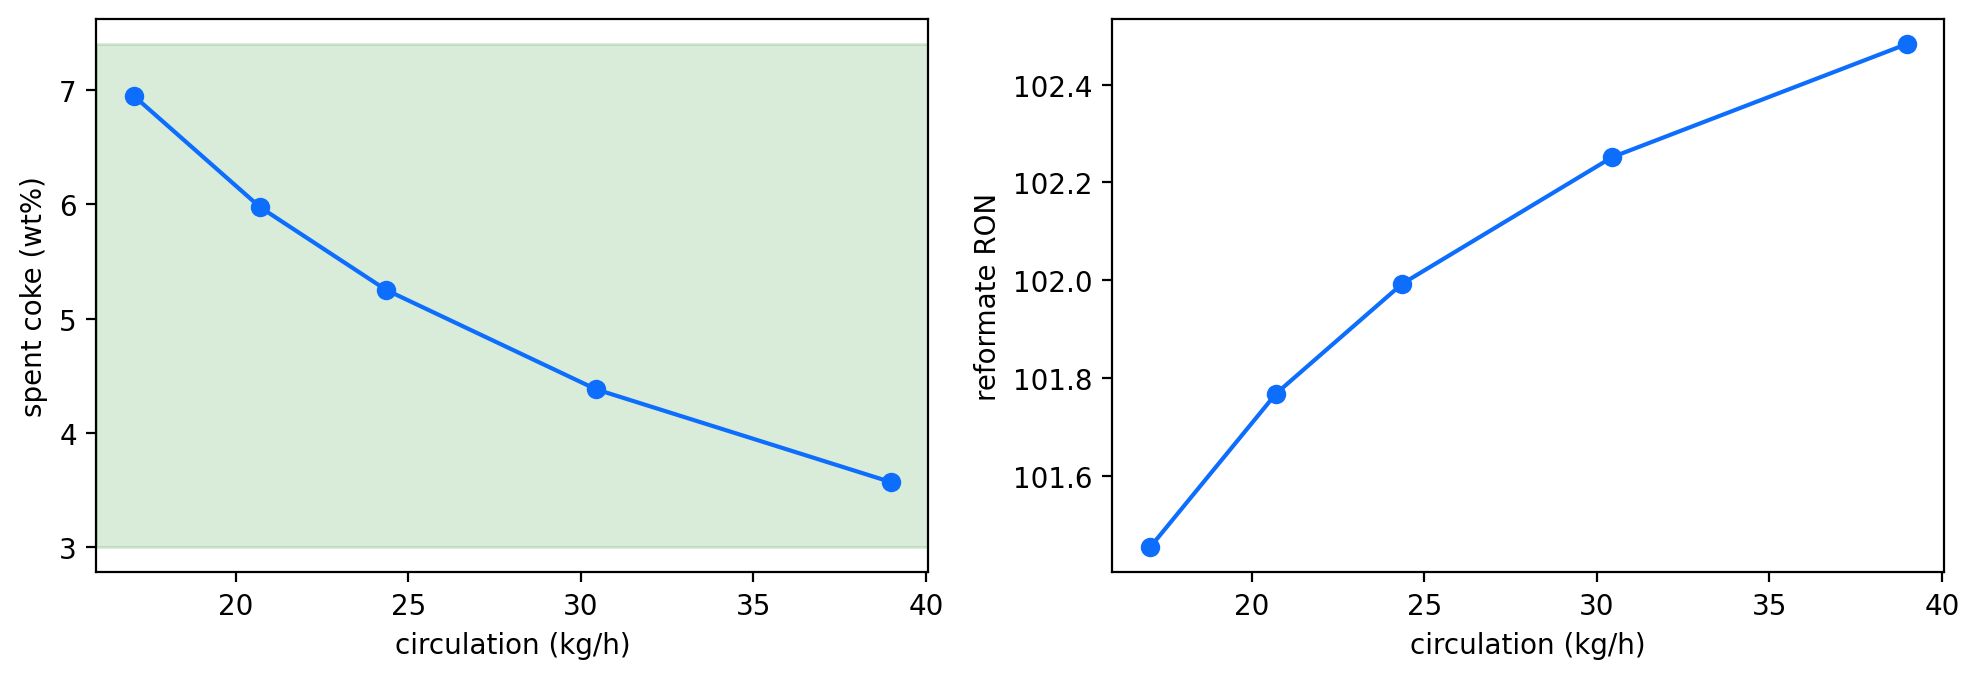

In [5]:
G0 = float(base.ccr.circulation)
factors = [0.7, 0.85, 1.0, 1.25, 1.6]
rows, tear = [], base.tear
for f in factors:
    r = ccr.solve(feed, ccr.params, replace(base.ccr, circulation=f * G0), tear_initial=tear)
    tear = r.tear
    o = r.outputs()
    rows.append((f * G0 * 3600, float(o["ccr.spent_coke_wt"]), float(o["reformate.RON"]),
                 float(o["reformate.yield_vol"])))
rows = np.array(rows)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(rows[:, 0], rows[:, 1], "o-")
ax[0].axhspan(*CCR_ENVELOPE["spent_coke_wt"], color="g", alpha=0.15)
ax[0].set_xlabel("circulation (kg/h)"); ax[0].set_ylabel("spent coke (wt%)")
ax[1].plot(rows[:, 0], rows[:, 2], "o-")
ax[1].set_xlabel("circulation (kg/h)"); ax[1].set_ylabel("reformate RON")
plt.tight_layout()

The absolute circulation (about 24 kg/h for this 10 kg/s feed) is **not** a plant number: the
reformer's coke rate law is illustrative and low, so the catalyst turns over in about 36 days
instead of days. The *shape* of the trade-off is what the model offers.

## The regenerator

The burn-front temperature rise is set by the burn-zone O2 alone: the flue-gas recycle scales with the coke burned.

rise per 0.1 % O2: 11.1 K


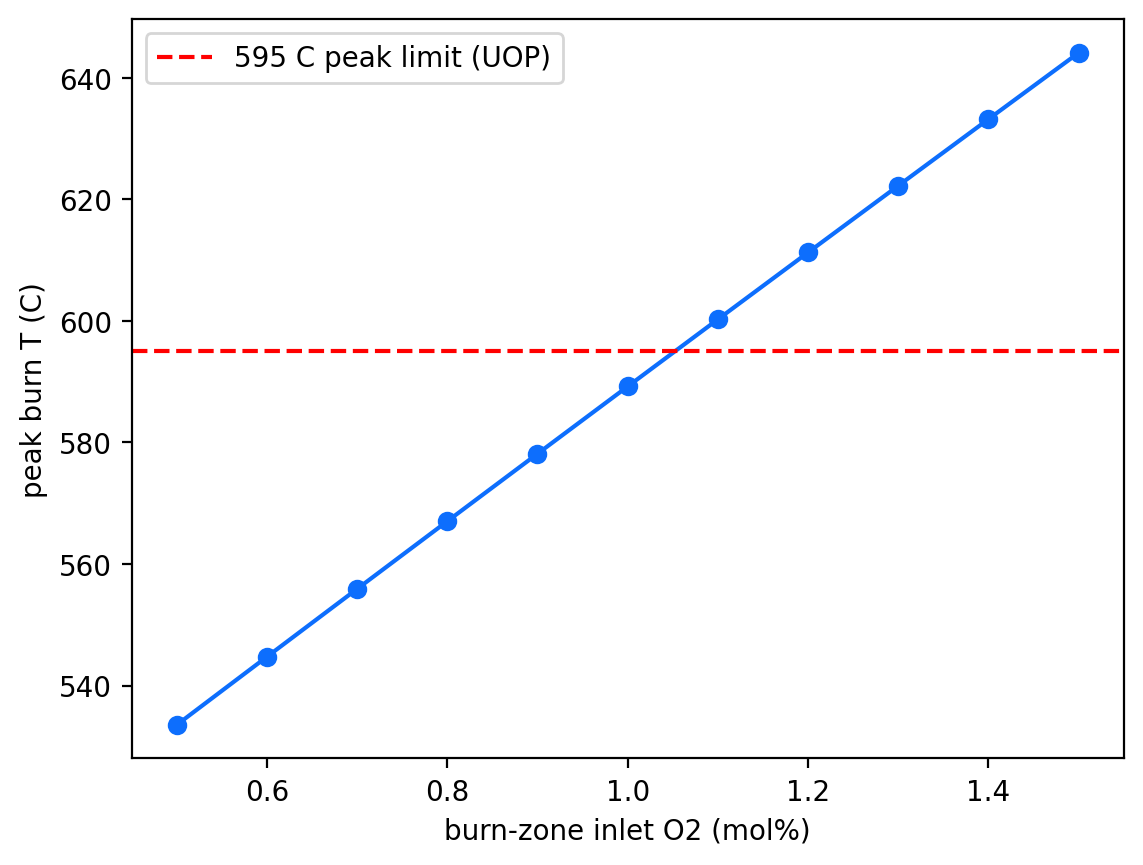

In [6]:
ys = np.linspace(0.005, 0.015, 11)
Tp = [float(Regenerator(RegeneratorParams(y_O2=y))(G0, base.coke[-1])["T_peak"]) - 273.15 for y in ys]
plt.plot(100 * ys, Tp, "o-")
plt.axhline(595, color="r", ls="--", label="595 C peak limit (UOP)")
plt.xlabel("burn-zone inlet O2 (mol%)"); plt.ylabel("peak burn T (C)"); plt.legend()
print(f"rise per 0.1 % O2: {(Tp[-1] - Tp[0]) / ((ys[-1] - ys[0]) / 0.001):.1f} K")

## Sensitivities

Forward-mode derivatives of spent coke and RON with respect to circulation and WAIT, through the coke-activity fixed point (implicit function theorem) and the H2 recycle. This takes several minutes.

In [7]:
def f(x):
    r = ccr.solve(feed, ccr.params.with_wait(x[1]), replace(base.ccr, circulation=x[0]),
                  tear_initial=base.tear)
    o = r.outputs()
    return jnp.stack([o["ccr.spent_coke_wt"], o["reformate.RON"]])

x0 = jnp.array([G0, float(ccr.params.wait)])
t = time.time()
J = jax.jacfwd(f)(x0)
print(f"{time.time() - t:.0f} s")
print(f"d(spent coke wt%)/d(circulation kg/h) = {float(J[0, 0]) / 3600:.4f}")
print(f"d(RON)/d(circulation kg/h)            = {float(J[1, 0]) / 3600:.4f}")
print(f"d(spent coke wt%)/d(WAIT K)           = {float(J[0, 1]):.4f}")
print(f"d(RON)/d(WAIT K)                      = {float(J[1, 1]):.4f}")

664 s
d(spent coke wt%)/d(circulation kg/h) = -0.1729
d(RON)/d(circulation kg/h)            = 0.0527
d(spent coke wt%)/d(WAIT K)           = 0.1331
d(RON)/d(WAIT K)                      = 0.5027
